# When does a backup request make the queue slower?

Two replicas share two worker slots. If a primary is still running after 1.177 ms, the hedged policy sends a second copy. Both copies run to completion. Would you enable the timer at 400 requests per second? What about 1,600?

Use 36,800 measured requests from 12 host-local runs to compare deadline misses and count the extra work. Change the deadline to try the comparison yourself. The notebook requires Python 3, Matplotlib and a public 1.3 MB download.

[Experiment and load generator](https://github.com/pgg898200-ship-it/cachepin/tree/8f963f09edf68942f9ac6e304e7635d4cf41a27e/experiments/shared-slots) · [Trace and column definitions](https://huggingface.co/datasets/pgg-engineering/racecurve-hedge-traces)

In [1]:
import csv
import gzip
import hashlib
import io
from collections import defaultdict
from urllib.request import urlopen

dataset = "https://huggingface.co/datasets/pgg-engineering/racecurve-hedge-traces"
revision = "efd1d491158d8b5ac4ff787f05dd05196700d60c"
with urlopen(f"{dataset}/resolve/{revision}/data/shared-slots.csv.gz", timeout=60) as response:
    compressed = response.read()
assert hashlib.sha256(compressed).hexdigest() == "ea2b1383a4ae39922f8b5ae1a7f9a989bc3a3b06a11811c9327e41cd47035e26"

with gzip.open(io.BytesIO(compressed), "rt", encoding="utf-8") as stream:
    rows = list(csv.DictReader(stream))
print(f"{len(rows):,} logical requests")

36,800 logical requests


## Count from the planned arrival

Start the clock at the planned arrival so queueing and dispatch delay count toward the deadline. Stop at the first completed copy. A nonnegative backup dispatch timestamp means the second copy launched. Pool both seeds within each load and policy.

Change `deadline_ms` and rerun the next two cells. The observed timestamps let you vary the deadline. Testing a different launch timer requires a fresh run because the number of jobs in the queue can change.

In [2]:
deadline_ms = 6
deadline_ns = round(deadline_ms * 1_000_000)
assert deadline_ns > 0, "Choose a positive deadline."

totals = defaultdict(lambda: {"requests": 0, "misses": 0, "backups": 0})
for row in rows:
    key = int(row["offered_rps"]), row["arm"]
    latency_ns = int(row["first_ns"]) - int(row["planned_ns"])
    totals[key]["requests"] += 1
    totals[key]["misses"] += latency_ns > deadline_ns
    totals[key]["backups"] += int(row["backup_submit_ns"]) >= 0

print("Requests/s  Policy    Requests  Backups   Misses   Miss rate")
for (rate, arm), counts in sorted(totals.items()):
    n, misses, backups = (counts[key] for key in ("requests", "misses", "backups"))
    print(f"{rate:10,}  {arm:7}  {n:8,}  {backups:7,}  {misses:7,}  {100 * misses / n:8.1f}%")

Requests/s  Policy    Requests  Backups   Misses   Miss rate
       400  control     1,600        0      161      10.1%
       400  hedge       1,600      261       21       1.3%
     1,600  control     6,400        0    1,722      26.9%
     1,600  hedge       6,400    6,350    6,324      98.8%
     2,600  control    10,400        0   10,212      98.2%
     2,600  hedge      10,400   10,371   10,338      99.4%


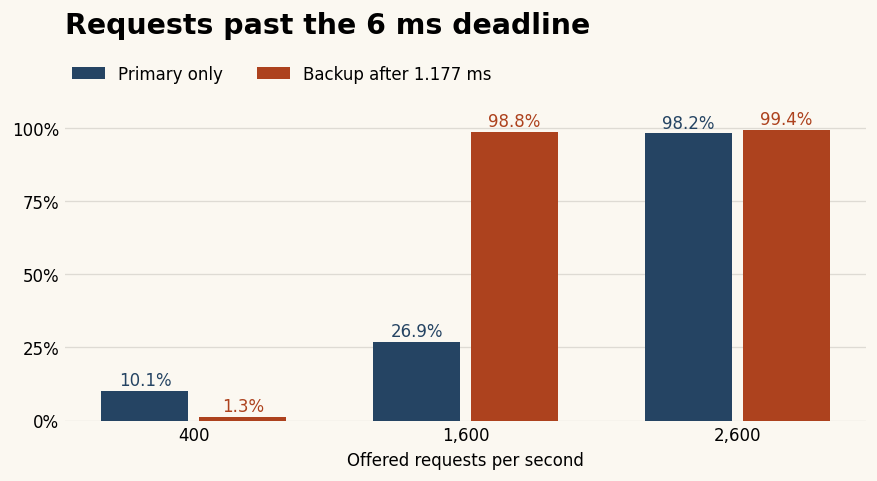

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rates = sorted({rate for rate, arm in totals})
fig, ax = plt.subplots(figsize=(7.2, 3.9), constrained_layout=True)
paper = "#fbf8f1"
fig.set_facecolor(paper)
ax.set_facecolor(paper)
for arm, label, color, offset in [
    ("control", "Primary only", "#254463", -0.18),
    ("hedge", "Backup after 1.177 ms", "#ad421e", 0.18),
]:
    x = [i + offset for i in range(len(rates))]
    pct = [100 * totals[rate, arm]["misses"] / totals[rate, arm]["requests"] for rate in rates]
    ax.bar(x, pct, width=0.32, color=color, label=label, zorder=2)
    for pos, val in zip(x, pct):
        ax.text(pos, val + 2, f"{val:.1f}%", ha="center", size=10, color=color)
ax.set_title(f"Requests past the {deadline_ms:g} ms deadline", loc="left", weight="bold", pad=36, size=17)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False, borderaxespad=0)
ax.set_xticks(range(len(rates)), [f"{rate:,}" for rate in rates])
ax.set_xlabel("Offered requests per second")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100])
ax.grid(axis="y", color="#dedbd4", zorder=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
plt.show()

## Read the 6 ms result

At 400 requests/s, 261 backups cut missed deadlines from 161 to 21 across 1,600 requests per policy. At 1,600 requests/s, the timer launched 6,350 backups for 6,400 requests. Misses rose from 1,722 to 6,324. Nearly every request added another job to the same constrained pool. At 2,600 requests/s, both policies missed over 98% of deadlines.

These short runs used two workload seeds, fixed arrival rates and uncancelled copies on one host. For a service that cancels losers, measure how much work actually stops and where replicas share capacity. The three load points establish a reversal on this workload. They do not identify a safe timer setting for another service.

[Try a paired-request replay in Racecurve](https://huggingface.co/spaces/pgg-engineering/racecurve) · [Per-run measurements](https://github.com/pgg898200-ship-it/cachepin/tree/8f963f09edf68942f9ac6e304e7635d4cf41a27e/experiments/shared-slots/measured)